# 04 · Cambio de dominio entre train y test

**Problema:** la CNN del notebook 03 ganaba al baseline al validar entre cámaras (42,3 frente a 61,7), pero en Kaggle sacó **72,3**, frente a **64,9** del baseline. Algo distingue al test que la validación entre Motorola y Samsung no recoge.

**Hipótesis:** las fotos de train no vienen tal como salen del móvil. Alguien las **redujo a ~4,6 px/mm y las recomprimió en JPEG**. Las de test vienen del iPhone a resolución completa. La textura fina que ve la CNN es distinta aunque la escala física sea la misma.

**Plan:**
1. Comprobar la hipótesis en los propios archivos.
2. Medir cuánto se distinguen train y test con un **clasificador de dominio**: si un modelo sabe decir de qué conjunto viene una foto, hay cambio de dominio.
3. Reproducir en las fotos de test la cadena de procesado del train y ver si el cambio se reduce.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from soilgrain.data import TRAIN_PIPELINE_PPM, TRAIN_PIPELINE_QUALITY, load_labels, load_photo, photo_index
from soilgrain.embeddings import load_backbone, patch_embeddings
from soilgrain.features import TARGET_PPM, photo_features
from soilgrain.metrics import SIEVES, emd, make_valid
from soilgrain.model import MonotoneHead
from soilgrain.plotting import GRID, INK, INK_2, set_style
from soilgrain.train_final import train_heads

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
FIG = ROOT / "reports" / "figures"
PROCESSED = ROOT / "data" / "processed"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

labels = load_labels()
photos = photo_index()
is_test = (photos["split"] == "test").values

## 1. Evidencia en los archivos

In [2]:
IJG_LUMA = np.array([16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55, 14, 13, 16, 24, 40, 57, 69, 56,
                     14, 17, 22, 29, 51, 87, 80, 62, 18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
                     49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99])

def jpeg_quality(path):
    """Calidad IJG aproximada a partir de la tabla de cuantización de luminancia."""
    with Image.open(path) as im:
        scale = np.mean(np.array(im.quantization[0], dtype=float) / IJG_LUMA) * 100
        has_exif = len(im.getexif()) > 0
    return (200 - scale) / 2 if scale <= 100 else 5000 / scale, has_exif

photos[["jpeg_q", "exif"]] = [jpeg_quality(p) for p in photos["path"]]
(photos.groupby(["split", "phone"])
       .agg(fotos=("path", "size"), resolucion=("width", "first"), px_mm=("ppm", "mean"),
            calidad_jpeg=("jpeg_q", "median"), con_exif=("exif", "mean"))
       .round(2))

fotos  resolucion  px_mm calidad_jpeg con_exif
split phone                                                                  
test  iPhone 14                   14        4032  13.94    93.016502      1.0
      iPhone 16                   21        5712  19.52    93.016502      1.0
train Motorola Edge               69         720   4.60    74.746855      0.0
      Motorola Edge 60 Fusion      3        4096  12.46    95.037062      1.0
      Samsung A52                 55        1599   4.55    74.746855      0.0

**Confirmado:** las fotos de Motorola Edge y Samsung del train tienen calidad JPEG ~75, sin metadatos EXIF y a ~4,6 px/mm: fueron reducidas y vueltas a guardar. Las de iPhone del test conservan el EXIF y una calidad ~93 a 14–20 px/mm. Las 3 fotos del Motorola Edge 60 Fusion son la excepción del train, porque vienen sin procesar.

Al reducir yo el test a 4,5 px/mm obtengo una imagen **más limpia** que las de train: sin artefactos JPEG y con otro filtro de reducción. Para una CNN, que se fija mucho en la textura fina, eso puede parecer otro tipo de suelo.

**Corrección:** `emulate_train_pipeline` reduce las fotos de alta resolución a 4,6 px/mm y las recomprime en JPEG de calidad 75 antes del reescalado final, igual que las de train.

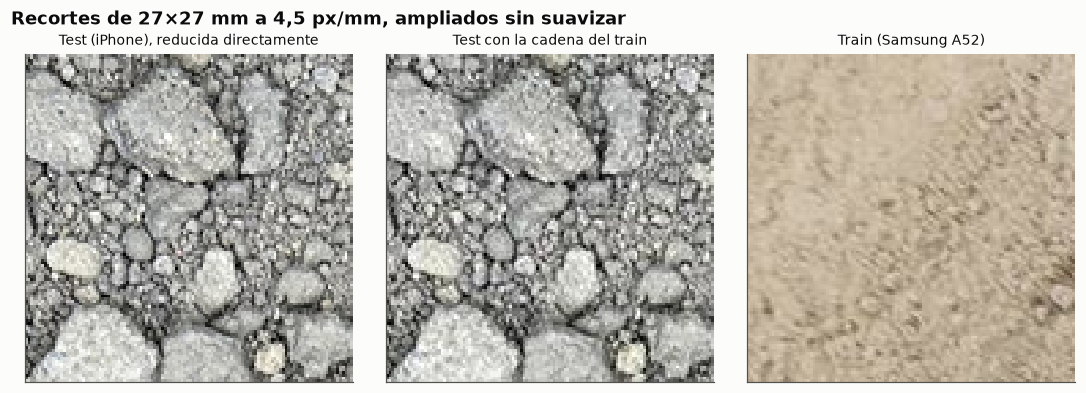

In [3]:
p = photos[is_test].iloc[0]
crop = lambda a: a[300:420, 300:420]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
q = photos[photos["phone"] == "Samsung A52"].iloc[0]
for ax, (img, title) in zip(axes, [
    (load_photo(p.path, TARGET_PPM, p.ppm), "Test (iPhone), reducida directamente"),
    (load_photo(p.path, TARGET_PPM, p.ppm, emulate_train=True), "Test con la cadena del train"),
    (load_photo(q.path, TARGET_PPM, q.ppm), "Train (Samsung A52)"),
]):
    ax.imshow(crop(img), interpolation="nearest")
    ax.set_title(title, fontsize=9, fontweight="normal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Recortes de 27×27 mm a 4,5 px/mm, ampliados sin suavizar", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "12_cadena_procesado.png", dpi=150, bbox_inches="tight")

## 2. Embeddings y features con y sin emulación

In [4]:
BACKBONE = "convnext_tiny.fb_in22k"
base = np.load(PROCESSED / f"emb_convnext_tiny_color_ppm{TARGET_PPM}.npz")
patch_emb = {"original": [base[str(i)] for i in range(len(photos))]}

cache = PROCESSED / f"emb_convnext_tiny_color_ppm{TARGET_PPM}_emulado.npz"
needs = photos["ppm"] > TRAIN_PIPELINE_PPM * 1.2
if cache.exists():
    z = np.load(cache)
    patch_emb["emulado"] = [z[str(i)] for i in range(len(photos))]
else:
    backbone = load_backbone(BACKBONE)
    patch_emb["emulado"] = [
        patch_embeddings(load_photo(p.path, TARGET_PPM, p.ppm, emulate_train=True), backbone) if n else patch_emb["original"][i]
        for i, (p, n) in enumerate(zip(photos.itertuples(), needs))
    ]
    np.savez_compressed(cache, **{str(i): e for i, e in enumerate(patch_emb["emulado"])})
photo_emb = {k: np.stack([e.mean(0) for e in v]) for k, v in patch_emb.items()}

tex_orig = pd.read_csv(PROCESSED / f"features_ppm{TARGET_PPM}.csv").set_index("file").loc[photos["path"].map(lambda p: p.name)]
tex_cache = PROCESSED / f"features_ppm{TARGET_PPM}_emulado.csv"
if tex_cache.exists():
    tex_emul = pd.read_csv(tex_cache).set_index("file")
else:
    tex_emul = tex_orig.copy()
    for i, p in enumerate(photos.itertuples()):
        if needs.iat[i]:
            tex_emul.iloc[i] = pd.Series(photo_features(load_photo(p.path, TARGET_PPM, p.ppm, emulate_train=True)))[tex_emul.columns]
    tex_emul.reset_index().to_csv(tex_cache, index=False)
tex_emul = tex_emul.loc[photos["path"].map(lambda p: p.name)]
CAMERA_SENSITIVE = ("lum_mean", "lum_std", "lum_p10", "lum_p90", "chroma_r", "chroma_g")
TEX_COLS = [c for c in tex_orig.columns if c != "n_patches" and not c.startswith(CAMERA_SENSITIVE)]
tex = {"original": tex_orig[TEX_COLS].values, "emulado": tex_emul[TEX_COLS].values}
print(f"Fotos reprocesadas: {needs.sum()} ({(needs & is_test).sum()} de test y {(needs & ~is_test).sum()} del Motorola Edge 60 Fusion)")

Fotos reprocesadas: 38 (35 de test y 3 del Motorola Edge 60 Fusion)


## 3. Clasificador de dominio

Entreno una regresión logística para distinguir **fotos de test de fotos de train** usando las mismas features que ven los modelos. Agrupo por muestra en la validación cruzada para que no memorice muestras concretas.

- **AUC ≈ 0,5**: no sabe distinguirlas; train y test se parecen.
- **AUC ≈ 1**: las distingue perfectamente; hay un cambio de dominio que el modelo de suelos también notará.

Si la emulación funciona, el AUC debería bajar.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def domain_auc(X):
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
    proba = cross_val_predict(clf, X, is_test, groups=photos["sample_id"], cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
    return roc_auc_score(is_test, proba)

auc = pd.DataFrame({
    "CNN (embeddings)": {k: domain_auc(v) for k, v in photo_emb.items()},
    "Textura (features 02)": {k: domain_auc(v) for k, v in tex.items()},
}).T
auc.columns = ["sin emulación", "con emulación"]
auc.round(3)

,sin emulación,con emulación
CNN (embeddings),0.996,0.995
Textura (features 02),0.932,0.933


**La emulación no cambia nada:** el AUC sigue siendo prácticamente 1. Pero antes de concluir que el cambio de dominio es enorme, hace falta un **control**: ¿distingue el clasificador también entre las dos cámaras del train, fotografiando *las mismas muestras*?

In [6]:
pair = photos["phone"].isin(["Motorola Edge", "Samsung A52"]).values
is_sams = (photos["phone"] == "Samsung A52").values
clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
proba = cross_val_predict(clf, photo_emb["original"][pair], is_sams[pair], groups=photos["sample_id"][pair],
                          cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]
print(f"AUC Samsung frente a Motorola (mismas muestras, embeddings CNN): {roc_auc_score(is_sams[pair], proba):.3f}")

AUC Samsung frente a Motorola (mismas muestras, embeddings CNN): 0.997


**El control también da ~1.** Con 768 dimensiones, cualquier cámara deja una huella que se identifica perfectamente, y sin embargo entre esas dos cámaras la CNN valida bien (EMD de 42 entre cámaras). Así que **un AUC alto no mide cuánto perjudica el cambio de dominio**, solo que existe. Es una herramienta que hay que usar con un control al lado.

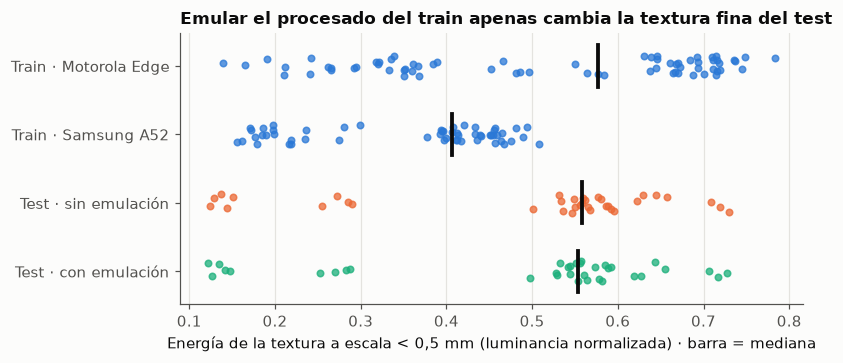

In [7]:
fine = TEX_COLS.index("band_0.5mm")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
groups = [
    ("Train · Motorola Edge", tex["original"][photos["phone"].eq("Motorola Edge").values, fine], "#2a78d6"),
    ("Train · Samsung A52", tex["original"][photos["phone"].eq("Samsung A52").values, fine], "#2a78d6"),
    ("Test · sin emulación", tex["original"][is_test, fine], "#eb6834"),
    ("Test · con emulación", tex["emulado"][is_test, fine], "#1baf7a"),
]
for i, (name, v, color) in enumerate(groups):
    ax.scatter(v, np.full(len(v), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(v)), s=18, color=color, alpha=0.75, zorder=3)
    ax.plot([np.median(v)] * 2, [i - 0.3, i + 0.3], color=INK, lw=2.5, zorder=4)
ax.set_yticks(range(len(groups)), [g[0] for g in groups])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Energía de la textura a escala < 0,5 mm (luminancia normalizada) · barra = mediana")
ax.set_title("Emular el procesado del train apenas cambia la textura fina del test", loc="left")
fig.tight_layout()
fig.savefig(FIG / "13_textura_fina_dominio.png", dpi=150, bbox_inches="tight")

## 4. Efecto en las predicciones de test

No hay etiquetas de test, así que no puedo medir el error. Sí puedo ver **cuánto cambian las predicciones** y si dejan de ser tan extremas. Los modelos se reentrenan con todo el train: solo cambian las 3 fotos del Motorola Edge 60 Fusion, que también se emulan.

In [8]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

train_idx = np.where(~is_test)[0]
y_photo = labels.reindex(photos["sample_id"]).values
template = pd.read_csv(ROOT / "data" / "raw" / "sample_submission.csv")

def by_sample(per_photo):
    df = pd.DataFrame(per_photo, index=photos["sample_id"].values[is_test])
    return pd.DataFrame(make_valid(df.groupby(level=0).mean().loc[template["sample_id"]].values),
                        index=template["sample_id"], columns=template.columns[1:])

def predict_ridge(X):
    model = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": np.logspace(-1, 4, 11)},
                         cv=GroupKFold(n_splits=5), scoring="neg_mean_absolute_error")
    model.fit(X[train_idx], y_photo[train_idx][:, :-1], groups=photos["sample_id"].values[train_idx])
    return by_sample(np.c_[model.predict(X[is_test]), np.full(is_test.sum(), 100)])

def predict_cnn(embs):
    X = np.concatenate([embs[i] for i in train_idx])
    sids = np.concatenate([[photos["sample_id"].iat[i]] * len(embs[i]) for i in train_idx])
    bundle = train_heads(X, labels.loc[sids].values, sids, device=DEVICE)
    mu, sd = (torch.tensor(bundle[k], dtype=torch.float32, device=DEVICE) for k in ("mu", "sd"))
    heads = []
    for state in bundle["states"]:
        h = MonotoneHead(bundle["in_features"], hidden=bundle["hidden"]).to(DEVICE)
        h.load_state_dict(state)
        heads.append(h.eval())
    out = []
    with torch.no_grad():
        for i in np.where(is_test)[0]:
            x = (torch.tensor(embs[i], device=DEVICE) - mu) / sd
            out.append(torch.stack([h(x).mean(0) for h in heads]).mean(0).cpu().numpy())
    return by_sample(np.array(out))

preds = {
    ("Textura", "original"): predict_ridge(tex["original"]),
    ("Textura", "emulado"): predict_ridge(tex["emulado"]),
    ("CNN", "original"): predict_cnn(patch_emb["original"]),
    ("CNN", "emulado"): predict_cnn(patch_emb["emulado"]),
}
summary = pd.DataFrame({
    f"{m} · {v}": {
        "% medio que pasa 0,063 mm": p["0.063"].mean(),
        "muestras con > 90 % bajo 0,2 mm": (p["0.2"] > 90).sum(),
        "EMD frente a la versión original": emd(preds[(m, "original")].values, p.values).mean(),
    } for (m, v), p in preds.items()
}).T
print("Referencia train: % medio que pasa 0,063 mm =", round(labels[0.063].mean(), 1),
      "· muestras con > 90 % bajo 0,2 mm =", int((labels[0.2] > 90).sum()), "de", len(labels))
summary.round(1)

Referencia train: % medio que pasa 0,063 mm = 30.2 · muestras con > 90 % bajo 0,2 mm = 6 de 24


,"% medio que pasa 0,063 mm","muestras con > 90 % bajo 0,2 mm",EMD frente a la versión original
Textura · original,34.2,0.0,0.0
Textura · emulado,34.0,0.0,0.8
CNN · original,38.1,6.0,0.0
CNN · emulado,35.9,6.0,4.3


In [9]:
SUBMISSIONS = ROOT / "submissions"
for (m, v), p in preds.items():
    if v == "emulado":
        out = SUBMISSIONS / f"{'cnn' if m == 'CNN' else 'baseline_ridge_robust'}_emulado.csv"
        assert (np.diff(p.values, axis=1) >= 0).all() and (p.values[:, -1] == 100).all()
        p.round(4).to_csv(out, index_label="sample_id")
        print("Guardado en", out.relative_to(ROOT))

Guardado en submissions/baseline_ridge_robust_emulado.csv
Guardado en submissions/cnn_emulado.csv


### Combinación de los dos modelos

Las predicciones de test de la textura y la CNN discrepan mucho entre sí. La EMD es una suma de valores absolutos, así que cumple la desigualdad triangular: para cada muestra, el error de la **media de dos curvas** nunca supera la media de los dos errores. Es decir, la combinación garantiza en el test una EMD no mayor que (64,9 + 72,3) / 2 ≈ 68,6, y puede quedar por debajo de ambas si los errores van en sentidos opuestos. Con un leaderboard tan ruidoso, es la forma más segura de **no depender de acertar con un solo modelo**.

In [10]:
blend = (preds[("Textura", "original")] + preds[("CNN", "original")]) / 2
blend = pd.DataFrame(make_valid(blend.values), index=blend.index, columns=blend.columns)
out = SUBMISSIONS / "media_textura_cnn.csv"
blend.round(4).to_csv(out, index_label="sample_id")
print("Guardado en", out.relative_to(ROOT))
print("EMD entre la combinación y cada modelo:",
      {k: round(emd(blend.values, preds[(k, "original")].values).mean(), 1) for k in ("Textura", "CNN")})

Guardado en submissions/media_textura_cnn.csv
EMD entre la combinación y cada modelo: {'Textura': np.float64(19.9), 'CNN': np.float64(19.9)}


## Conclusiones

1. **Hipótesis descartada.** Las fotos de train sí se redujeron y recomprimieron (JPEG ~75, sin EXIF), pero reproducir ese procesado en el test apenas cambia las features ni las predicciones. La diferencia entre la CNN y el baseline en Kaggle no se explica por ahí.
2. **Un clasificador de dominio necesita un control.** Distingue train de test con AUC ~1, pero también distingue dos cámaras de las mismas muestras con AUC ~1. En alta dimensión siempre hay huella de la cámara; lo que importa es si afecta a la variable objetivo, y eso solo lo mide una validación con etiquetas.
3. **La explicación más probable es más simple:** el test viene de **otras obras** (Airbus, Kleinkummerfeld, Münster…) que no están en el train, con suelos de otro aspecto (en la figura 12, grava gris y angulosa frente a los suelos beige típicos del train), y la puntuación pública se calcula sobre muy pocas muestras. Una diferencia de 7 puntos entre dos modelos que discrepan mucho puede ser simple ruido.
4. **Decisión:** para la selección final propongo la **combinación textura + CNN**, porque acota el riesgo por construcción. No sustituye a tener más datos, pero es la decisión más defendible con lo que hay.